Audio engineering basics

Load Audio + Inspect Basics

In [1]:
from pydub import AudioSegment

In [3]:
audio = AudioSegment.from_file("song.mp3")

In [4]:
print("Duration (ms):", len(audio))
print("Channels:", audio.channels)
print("Frame Rate:",audio.frame_rate)
print("Sample width (bytes):", audio.sample_width)
print("dBFS (average loudness):",audio.dBFS)

Duration (ms): 122609
Channels: 2
Frame Rate: 44100
Sample width (bytes): 2
dBFS (average loudness): -16.54416277964012


2.Slicing Audio (Show Output Sizes)

In [5]:
first_5_sec = audio[:5000]
next_5_sec = audio[5000:10000]

print("First 5 sec duration:",len(first_5_sec))
print("First 5 sec duration:",len(next_5_sec))

First 5 sec duration: 5000
First 5 sec duration: 5000


Fade In / Fade Out Demo

In [6]:
fade_in_clip = audio[:5000].fade_in(3000)
fade_out_clip = audio[:5000].fade_out(3000)

print("Fade-in clip:",fade_in_clip)
print("Fade-out clip:",fade_out_clip)

Fade-in clip: <pydub.audio_segment.AudioSegment object at 0x00000264E7B34950>
Fade-out clip: <pydub.audio_segment.AudioSegment object at 0x00000264E63D2F30>


Concatenation Demo

how to join 2 songs

In [7]:
combined = first_5_sec + next_5_sec
print("Combined length:",len(combined))

Combined length: 10000


Simple Waveform plot using librosa + matplotlib

peaks = loud parts

valleys = quiet parts

they visually understands fade, slicing, transitions

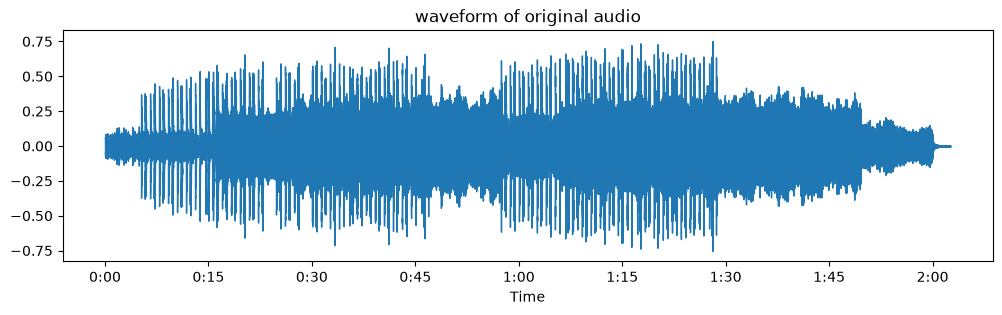

In [10]:
import librosa
import librosa.display
import matplotlib.pyplot as plt

y, sr = librosa.load("song.mp3", sr = None)

plt.figure(figsize = (12,3))
librosa.display.waveshow(y, sr=sr)
plt.title("waveform of original audio")
plt.show()

Visualize fade-in vs fade-out

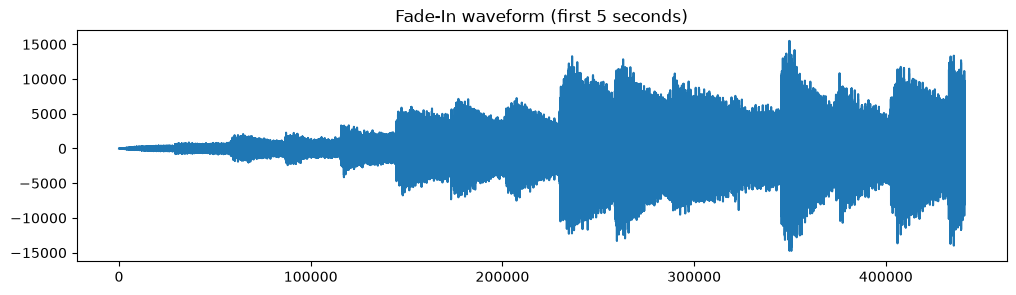

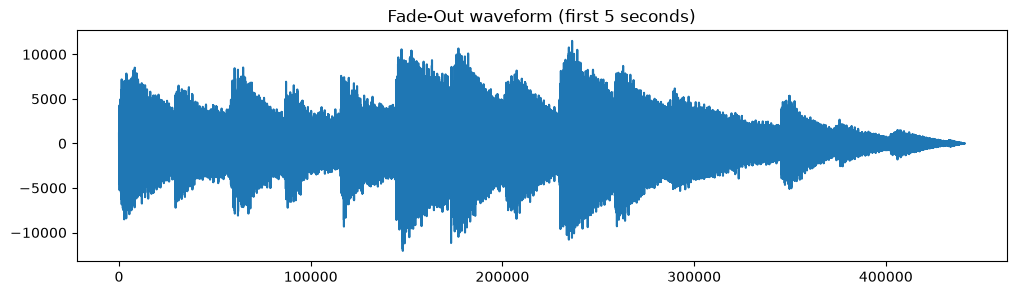

In [ ]:
fade_in_audio = fade_in_clip.get_array_of_samples()
fade_out_audio = fade_out_clip.get_array_of_samples()

plt.figure(figsize=(12,3))
plt.plot(fade_in_audio)
plt.title("Fade-In waveform (first 5 seconds)")
plt.show()

plt.figure(figsize=(12,3))
plt.plot(fade_out_audio)
plt.title("Fade-Out waveform (first 5 seconds)")
plt.show()

Logic

In [13]:
from pydub import AudioSegment
import os, random

Mixtape Generator

In [15]:
def smooth_fade_mixtape(folder, output="output/mixtape.mp3", transition_ms=6000):
    files = [f for f in os.listdir(folder) if f.endswith((".mp3",".wav"))]
    random.shuffle(files)  #shuffle for variety

    mixtape = None
    for i, file in enumerate(files):
        song = AudioSegment.from_file(os.path.join(folder, file))
        song = song.set_channels(2).set_frame_rate(44100)  #stereo

        if mixtape is None:
            mixtape = song

        else:
            # define overlap region
            overlap = min(transition_ms, len(song), len(mixtape))

            # outgoing: fade out + high-pass to remove bass
            outgoing = mixtape[-overlap:].fade_out(overlap).low_pass_filter(4000)

            #incoming: fade in + low-pass to smooth highs
            incoming = song[:overlap].fade_in(overlap).low_pass_filter(4000)

            #overlay transition
            transition = outgoing.overlay(incoming)

            mixtape = mixtape[:-overlap] + transition + song[overlap:]
        
    mixtape.export(output, format="mp3")
    print(f"Smooth fade mixtape generated: {output}")

smooth_fade_mixtape("mixtape")

Smooth fade mixtape generated: output/mixtape.mp3


<>:1: SyntaxWarning: invalid escape sequence '\m'
<>:1: SyntaxWarning: invalid escape sequence '\m'
C:\Users\sande\AppData\Local\Temp\ipykernel_24920\1464905637.py:1: SyntaxWarning: invalid escape sequence '\m'
  y, sr = librosa.load("output\mixtape.mp3", sr = None)


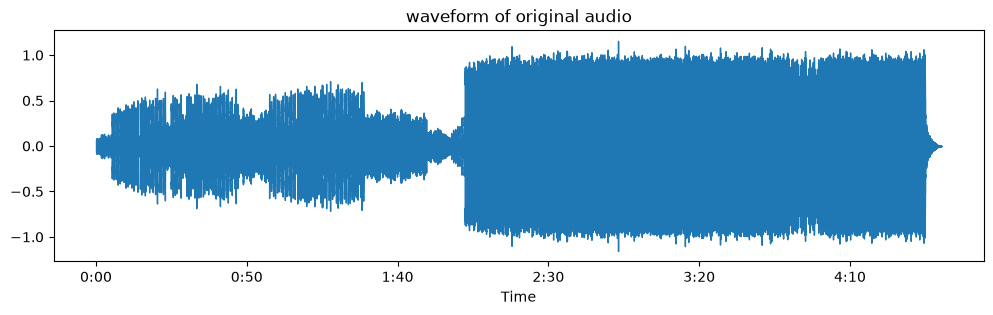

In [17]:
y, sr = librosa.load("output\mixtape.mp3", sr = None)

plt.figure(figsize = (12,3))
librosa.display.waveshow(y, sr=sr)
plt.title("waveform of original audio")
plt.show()

<>:1: SyntaxWarning: invalid escape sequence '\s'
<>:1: SyntaxWarning: invalid escape sequence '\s'
C:\Users\sande\AppData\Local\Temp\ipykernel_24920\1061852803.py:1: SyntaxWarning: invalid escape sequence '\s'
  y, sr = librosa.load("mixtape\song1.mp3", sr = None)


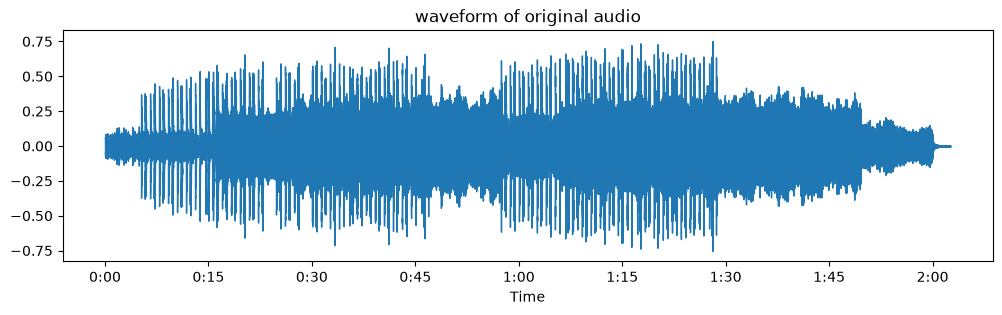

In [18]:
y, sr = librosa.load("mixtape\song1.mp3", sr = None)

plt.figure(figsize = (12,3))
librosa.display.waveshow(y, sr=sr)
plt.title("waveform of original audio")
plt.show()

<>:1: SyntaxWarning: invalid escape sequence '\s'
<>:1: SyntaxWarning: invalid escape sequence '\s'
C:\Users\sande\AppData\Local\Temp\ipykernel_24920\56573405.py:1: SyntaxWarning: invalid escape sequence '\s'
  y, sr = librosa.load("mixtape\song2.mp3", sr = None)


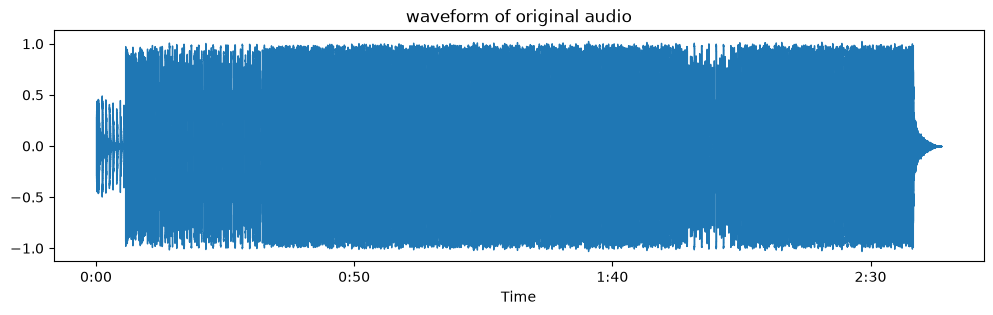

In [19]:
y, sr = librosa.load("mixtape\song2.mp3", sr = None)

plt.figure(figsize = (12,3))
librosa.display.waveshow(y, sr=sr)
plt.title("waveform of original audio")
plt.show()

Description Generator

In [20]:
import os
from pydub import AudioSegment

def generate_youtube_description_with_timestamps(track_folder, mixtape_name="Afro House Mixtape", genre="Afro House", start_time_sec=0):
    """
    Generates a YouTube description with tracklist, timestamps, and hashtags.
    Assumes audio files are in order of playback.
    """
    audio_extensions = (".mp3", ".wav", ".flac", ".aac", ".ogg", ".m4a")
    tracks = [f for f in os.listdir(track_folder) if f.lower().endswith(audio_extensions)]
    if not tracks:
        return "No audio tracks found in the folder!"

    tracks.sort()  # optional: sort alphabetically

    description = f"🔥 {mixtape_name} 🔥\n"
    description += f"Genre: {genre}\n\n"
    description += "🎵 Tracklist:\n"

    current_time = start_time_sec

    for idx, track in enumerate(tracks, 1):
        track_path = os.path.join(track_folder, track)
        audio = AudioSegment.from_file(track_path)
        duration_sec = len(audio) // 1000  # duration in seconds

        # Format timestamp mm:ss
        minutes = current_time // 60
        seconds = current_time % 60
        timestamp = f"{minutes:02d}:{seconds:02d}"

        track_name = os.path.splitext(track)[0]
        description += f"{timestamp} - {track_name}\n"

        current_time += duration_sec  # increment for next track

    description += "\n💽 Download/Listen links:\n"
    description += "You can find these tracks online or on Spotify/Apple Music.\n\n"
    description += "🎧 Follow for more Afro House mixes!\n\n"

    hashtags = [
        "#AfroHouse", "#HouseMusic", "#EDM", "#DanceMusic", "#Mixtape",
        "#ElectronicMusic", "#DJMix", "#PartyMusic", "#DeepHouse", "#AfroHouseVibes"
    ]
    description += " ".join(hashtags)

    return description

# Example usage
track_folder = r"mixtape"
description_text = generate_youtube_description_with_timestamps(
    track_folder,
    mixtape_name="Afro House Summer Mix",
    genre="Afro House"
)

print(description_text)

# Optional: save to file
with open("youtube_description.txt", "w", encoding="utf-8") as f:
    f.write(description_text)


🔥 Afro House Summer Mix 🔥
Genre: Afro House

🎵 Tracklist:
00:00 - song1
02:02 - song2

💽 Download/Listen links:
You can find these tracks online or on Spotify/Apple Music.

🎧 Follow for more Afro House mixes!

#AfroHouse #HouseMusic #EDM #DanceMusic #Mixtape #ElectronicMusic #DJMix #PartyMusic #DeepHouse #AfroHouseVibes


Video Generator

In [21]:
import subprocess
import os
from PIL import Image

In [22]:
def make_video_from_audio_optimized(image_path, audio_path, output_path="output/mixtape_vid3.mp4",
                                    video_resolution=(1280, 720), fps=1, preset="ultrafast"):

    if not os.path.exists(image_path):
        raise FileNotFoundError(f"Image not found: {image_path}")
    if not os.path.exists(audio_path):
        raise FileNotFoundError(f"Audio not found: {audio_path}")

    # Ensure output folder exists
    os.makedirs(os.path.dirname(output_path), exist_ok=True)

    # Resize image if necessary
    img_resized_path = "temp_resized_image.jpg"
    img = Image.open(image_path)
    img = img.resize(video_resolution)
    img.save(img_resized_path)

    # FFmpeg command
    cmd = ["ffmpeg",
        "-y",
        "-loop","1",
        "-i", img_resized_path,
        "-i", audio_path,
        "-c:v","libx264",
        "-preset", preset,
        "-tune", "stillimage",
        "-r", str(fps),
        "-c:a", "aac",
        "-b:a", "192k",
        "-shortest",
        output_path
    ]

    try:
        subprocess.run(cmd, check=True)
        print(f"Video created; {output_path}")
    except subprocess.CalledProcessError as e:
        print(" FFmpeg failed! Error: ",e)
    finally:
        # Clean up temporary resized image
        if os.path.exists(img_resized_path):
            os.remove(img_resized_path)


# Example usage
image_path = r"images/image.png"
audio_path = r"output/mixtape.mp3"
make_video_from_audio_optimized(image_path, audio_path)

Video created; output/mixtape_vid3.mp4
